# Conexiones imposibles 02: *Big* y *Men in Black*

**Categoría: EDA (análisis exploratorio de datos).** Describo datos existentes y no genero predicciones.

Quiero responder una pregunta concreta: ¿qué caminos documentados conectan dos películas separadas por nueve años y cuál de ellos entra de verdad en ambas películas?

## Ruta de lectura y glosario

Primero comparo su presencia en MovieLens; después cruzo el público, los géneros y las etiquetas; por último ordeno las conexiones de créditos y música.

- **Valoración:** nota de media a cinco estrellas.
- **Percentil de popularidad:** porcentaje de películas con menos valoraciones.
- **Correlación:** medida entre -1 y 1; cerca de cero indica que las notas de una película ayudan poco a anticipar las de la otra.
- **Etiqueta:** palabra o frase aportada por usuarios de MovieLens.

## Fuentes y unidad de análisis

Uso MovieLens 32M, con 32.000.204 valoraciones sobre 84.432 películas hasta el 12 de octubre de 2023. Cada fila del cruce representa a una persona que puntuó las dos películas. Compruebo los créditos en AFI, Amblin y Sony, y separo esas fuentes de la información musical.

In [1]:
# cargo los resultados ya calculados y conservo rutas relativas reproducibles
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

carpeta = Path.cwd()
resultados = json.loads((carpeta / 'resultados_movielens.json').read_text(encoding='utf-8'))
resumen = pd.read_csv(carpeta / 'resumen_movielens.csv')
compartidas = pd.read_csv(carpeta / 'valoraciones_compartidas.csv')
conexiones = pd.read_csv(carpeta / 'conexiones_comprobadas.csv')
resumen

,movie_id,pelicula,titulo_movielens,generos,valoraciones,media,mediana,desviacion,percentil_popularidad,etiquetas_totales,etiquetas_unicas
0,2797,Big,Big (1988),Comedy|Drama|Fantasy|Romance,24016,3.621,4.0,0.888,99.74,525,192
1,1580,Men in Black,Men in Black (a.k.a. MIB) (1997),Action|Comedy|Sci-Fi,48434,3.594,4.0,0.900,99.95,934,387


## Las dos parten de una ventaja: casi todo el mundo las conoce

*Big* reúne **24.016** valoraciones y supera al **99.74%** del catálogo en popularidad. *Men in Black* suma **48.434** y supera al **99.95%**. Esta comparación mide presencia en MovieLens. no calidad ni taquilla.

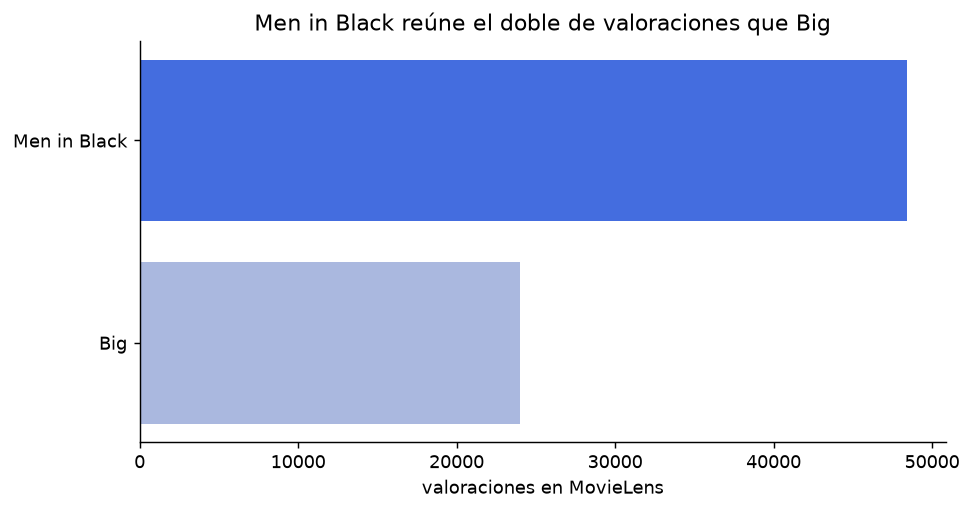

In [2]:
# dibujo la popularidad sin presentar el volumen de votos como una nota de calidad
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(resumen['pelicula'], resumen['valoraciones'], color=['#aab8df', '#446ddf'])
ax.set_title('Men in Black reúne el doble de valoraciones que Big')
ax.set_xlabel('valoraciones en MovieLens')
ax.set_ylabel('')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 15.741 espectadores entran en las dos salas

El cruce encuentra **15.741 personas**. Representan el **65.54%** de quienes puntuaron *Big* y el **32.5%** de quienes puntuaron *Men in Black*.

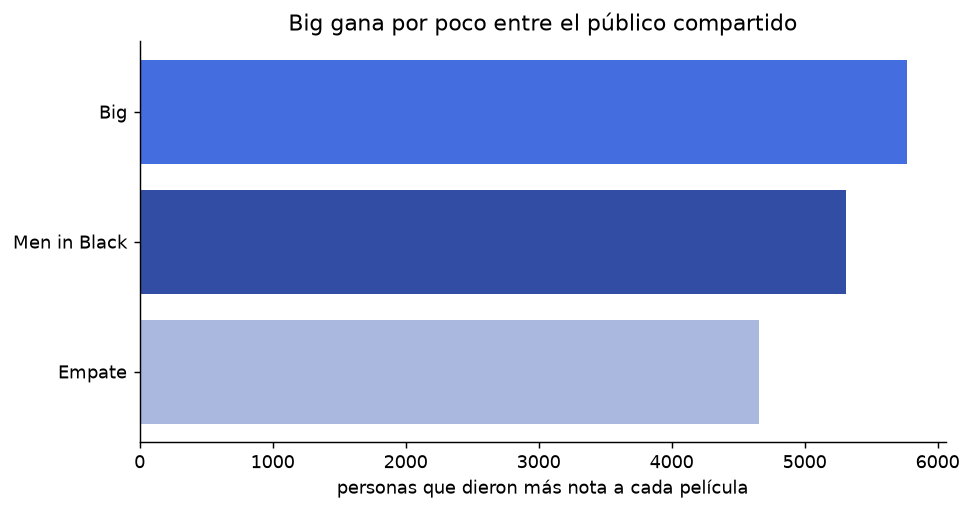

In [3]:
# comparo las preferencias solo dentro del grupo que puntuó ambas películas
preferencias = pd.Series(resultados['preferencias']).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(preferencias.index, preferencias.values, color=['#aab8df', '#314ea4', '#446ddf'])
ax.set_title('Big gana por poco entre el público compartido')
ax.set_xlabel('personas que dieron más nota a cada película')
ax.set_ylabel('')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

*Big* recibe más nota en **5.772** casos; *Men in Black*. en **5.309**; hay **4.660** empates. La correlación es **0.306**. una relación débil. Compartir público no basta para explicar el vínculo.

## Los géneros y las etiquetas abren pistas, no una respuesta

Las dos comparten un solo género: **comedia**. Entre cientos de etiquetas aparecen **14 coincidencias**, entre ellas identidad, Nueva York, protagonista masculino y béisbol. Son parecidos útiles para describirlas, pero ninguno demuestra una conexión de producción.

In [4]:
# muestro las coincidencias normalizadas para que el resultado pueda auditarse
pd.DataFrame({'etiqueta_compartida': resultados['etiquetas_compartidas']})

,etiqueta_compartida
0,baseball
1,baseball game
2,blockbuster
3,bully
4,clv
5,comedy
6,fantasy
7,foul language
8,identity
9,male protagonist


## Tres conexiones documentadas

Ordeno los hallazgos según lo cerca que entran en las películas. Barry Sonnenfeld es un crédito directo: fotografió *Big* y dirigió *Men in Black*. Anne Spielberg escribió *Big* y su hermano Steven produjo ejecutivamente *Men in Black*. El tercer camino ya no une carreras desde fuera: une lo que suena dentro de las obras.

In [5]:
# conservo cada conexión y sus fuentes sin mezclar hechos con interpretaciones
conexiones

,orden,tipo,conexion_origen,puente,conexion_destino,fuente_origen,fuente_destino
0,1,crédito,Big,Barry Sonnenfeld (director de fotografía),Men in Black (director),AFI Catalog,Amblin
1,2,familia y créditos,Big (guion de Anne Spielberg),Anne y Steven Spielberg son hermanos,Men in Black (producción ejecutiva de Steven Spielberg),AFI Catalog y biografía de Anne Spielberg,Sony Pictures Museum
2,3,música,Big incluye Forget Me Nots de Patrice Rushen,Men in Black reutiliza la composición y su base musical,Men in Black de Will Smith acredita a Patrice Rushen y Freddie Washington,AFI Catalog,Billboard y créditos discográficos


## Comprobaciones y limitaciones

MovieLens no representa a todo el público y sus etiquetas pueden contener ruido. Los porcentajes describen su comunidad, no a todos los espectadores. Los créditos permiten demostrar trabajos compartidos, pero no una influencia creativa. La conexión musical documenta una composición reutilizada; no implica que *Men in Black* tomara la idea de *Big*.

## Conclusión

Los datos encuentran varias respuestas verdaderas. Hay un público enorme en común, un género compartido, etiquetas parecidas, un director de fotografía que se convirtió en director y dos hermanos situados en los créditos. Sin embargo, la unión más literal es musical: *Forget Me Nots*, de Patrice Rushen, ya sonaba en *Big* y nueve años después sostuvo la canción *Men in Black* de Will Smith.